## 1. Import Libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

## 2. Load Dataset

In [32]:
df = pd.read_csv("german_credit_data.csv")

## 3. Data Preparation

In [33]:
df.shape

(1000, 21)

In [34]:
df.describe()

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,...,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2.577000,20.903000,2.54500,2.828000,3271.24800,2.105000,3.384000,2.973000,2.68200,1.145000,...,2.358000,35.54200,2.675000,1.928000,1.407000,2.904000,1.845000,1.404000,1.963000,0.700000
std,1.257638,12.058814,1.08312,2.744439,2822.75176,1.580023,1.208306,1.118715,0.70808,0.477706,...,1.050209,11.35267,0.705601,0.530186,0.577654,0.653614,0.362086,0.490943,0.188856,0.458487
min,1.000000,4.000000,0.00000,0.000000,250.00000,1.000000,1.000000,1.000000,1.00000,1.000000,...,1.000000,19.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,12.000000,2.00000,1.000000,1365.50000,1.000000,3.000000,2.000000,2.00000,1.000000,...,1.000000,27.00000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.000000
50%,2.000000,18.000000,2.00000,2.000000,2319.50000,1.000000,3.000000,3.000000,3.00000,1.000000,...,2.000000,33.00000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,1.000000
75%,4.000000,24.000000,4.00000,3.000000,3972.25000,3.000000,5.000000,4.000000,3.00000,1.000000,...,3.000000,42.00000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000
max,4.000000,72.000000,4.00000,10.000000,18424.00000,5.000000,5.000000,4.000000,4.00000,3.000000,...,4.000000,75.00000,3.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,1.000000


In [35]:
df = df.rename(columns={
    'laufkont': 'status_of_existing_accounts',
    'laufzeit': 'duration_of_credit_month',
    'moral': 'credit_history',
    'verw': 'purpose_of_loan',
    'hoehe': 'credit_amount',
    'sparkont': 'value_of_savings$bonds',
    'beszeit': 'years_of_present_employment',
    'rate': 'percentage_of_disposable_income',
    'famges': 'sex_and_marital_status',
    'buerge': 'guarantors',
    'wohnzeit': 'duration_in_present_residence',
    'verm': 'property',
    'alter': 'age_in_years',
    'weitkred': 'concurrent_credits',
    'wohn': 'housing',
    'bishkred': 'no_of_credits_at_this_bank',
    'beruf': 'occupation',
    'pers': 'no_of_dependents',
    'telef': 'telephone',
    'gastarb': 'foreign_worker',
    'kredit': 'creditability'
})

In [36]:
df.head()

,status_of_existing_accounts,duration_of_credit_month,credit_history,purpose_of_loan,credit_amount,value_of_savings$bonds,years_of_present_employment,percentage_of_disposable_income,sex_and_marital_status,guarantors,...,property,age_in_years,concurrent_credits,housing,no_of_credits_at_this_bank,occupation,no_of_dependents,telephone,foreign_worker,creditability
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


In [39]:
df.describe()

,status_of_existing_accounts,duration_of_credit_month,credit_history,purpose_of_loan,credit_amount,value_of_savings$bonds,years_of_present_employment,percentage_of_disposable_income,sex_and_marital_status,guarantors,...,property,age_in_years,concurrent_credits,housing,no_of_credits_at_this_bank,occupation,no_of_dependents,telephone,foreign_worker,creditability
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,...,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2.577000,20.903000,2.54500,2.828000,3271.24800,2.105000,3.384000,2.973000,2.68200,1.145000,...,2.358000,35.54200,2.675000,1.928000,1.407000,2.904000,1.845000,1.404000,1.963000,0.700000
std,1.257638,12.058814,1.08312,2.744439,2822.75176,1.580023,1.208306,1.118715,0.70808,0.477706,...,1.050209,11.35267,0.705601,0.530186,0.577654,0.653614,0.362086,0.490943,0.188856,0.458487
min,1.000000,4.000000,0.00000,0.000000,250.00000,1.000000,1.000000,1.000000,1.00000,1.000000,...,1.000000,19.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,12.000000,2.00000,1.000000,1365.50000,1.000000,3.000000,2.000000,2.00000,1.000000,...,1.000000,27.00000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.000000
50%,2.000000,18.000000,2.00000,2.000000,2319.50000,1.000000,3.000000,3.000000,3.00000,1.000000,...,2.000000,33.00000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,1.000000
75%,4.000000,24.000000,4.00000,3.000000,3972.25000,3.000000,5.000000,4.000000,3.00000,1.000000,...,3.000000,42.00000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000
max,4.000000,72.000000,4.00000,10.000000,18424.00000,5.000000,5.000000,4.000000,4.00000,3.000000,...,4.000000,75.00000,3.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,1.000000


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   status_of_existing_accounts      1000 non-null   int64
 1   duration_of_credit_month         1000 non-null   int64
 2   credit_history                   1000 non-null   int64
 3   purpose_of_loan                  1000 non-null   int64
 4   credit_amount                    1000 non-null   int64
 5   value_of_savings$bonds           1000 non-null   int64
 6   years_of_present_employment      1000 non-null   int64
 7   percentage_of_disposable_income  1000 non-null   int64
 8   sex_and_marital_status           1000 non-null   int64
 9   guarantors                       1000 non-null   int64
 10  duration_in_present_residence    1000 non-null   int64
 11  property                         1000 non-null   int64
 12  age_in_years                     1000 non-null   int64
 13  

In [42]:
df.columns

Index(['status_of_existing_accounts', 'duration_of_credit_month',
       'credit_history', 'purpose_of_loan', 'credit_amount',
       'value_of_savings$bonds', 'years_of_present_employment',
       'percentage_of_disposable_income', 'sex_and_marital_status',
       'guarantors', 'duration_in_present_residence', 'property',
       'age_in_years', 'concurrent_credits', 'housing',
       'no_of_credits_at_this_bank', 'occupation', 'no_of_dependents',
       'telephone', 'foreign_worker', 'creditability'],
      dtype='str')

In [46]:
#syntax: dataframe.nunique(axis=0,dropna=True)
df.nunique()

status_of_existing_accounts          4
duration_of_credit_month            33
credit_history                       5
purpose_of_loan                     10
credit_amount                      923
value_of_savings$bonds               5
years_of_present_employment          5
percentage_of_disposable_income      4
sex_and_marital_status               4
guarantors                           3
duration_in_present_residence        4
property                             4
age_in_years                        53
concurrent_credits                   3
housing                              3
no_of_credits_at_this_bank           4
occupation                           4
no_of_dependents                     2
telephone                            2
foreign_worker                       2
creditability                        2
dtype: int64

In [51]:
df.describe(include='all')

,status_of_existing_accounts,duration_of_credit_month,credit_history,purpose_of_loan,credit_amount,value_of_savings$bonds,years_of_present_employment,percentage_of_disposable_income,sex_and_marital_status,guarantors,...,property,age_in_years,concurrent_credits,housing,no_of_credits_at_this_bank,occupation,no_of_dependents,telephone,foreign_worker,creditability
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,...,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2.577000,20.903000,2.54500,2.828000,3271.24800,2.105000,3.384000,2.973000,2.68200,1.145000,...,2.358000,35.54200,2.675000,1.928000,1.407000,2.904000,1.845000,1.404000,1.963000,0.700000
std,1.257638,12.058814,1.08312,2.744439,2822.75176,1.580023,1.208306,1.118715,0.70808,0.477706,...,1.050209,11.35267,0.705601,0.530186,0.577654,0.653614,0.362086,0.490943,0.188856,0.458487
min,1.000000,4.000000,0.00000,0.000000,250.00000,1.000000,1.000000,1.000000,1.00000,1.000000,...,1.000000,19.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,12.000000,2.00000,1.000000,1365.50000,1.000000,3.000000,2.000000,2.00000,1.000000,...,1.000000,27.00000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.000000
50%,2.000000,18.000000,2.00000,2.000000,2319.50000,1.000000,3.000000,3.000000,3.00000,1.000000,...,2.000000,33.00000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,1.000000
75%,4.000000,24.000000,4.00000,3.000000,3972.25000,3.000000,5.000000,4.000000,3.00000,1.000000,...,3.000000,42.00000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000
max,4.000000,72.000000,4.00000,10.000000,18424.00000,5.000000,5.000000,4.000000,4.00000,3.000000,...,4.000000,75.00000,3.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,1.000000


# Exploratory Data Analysis

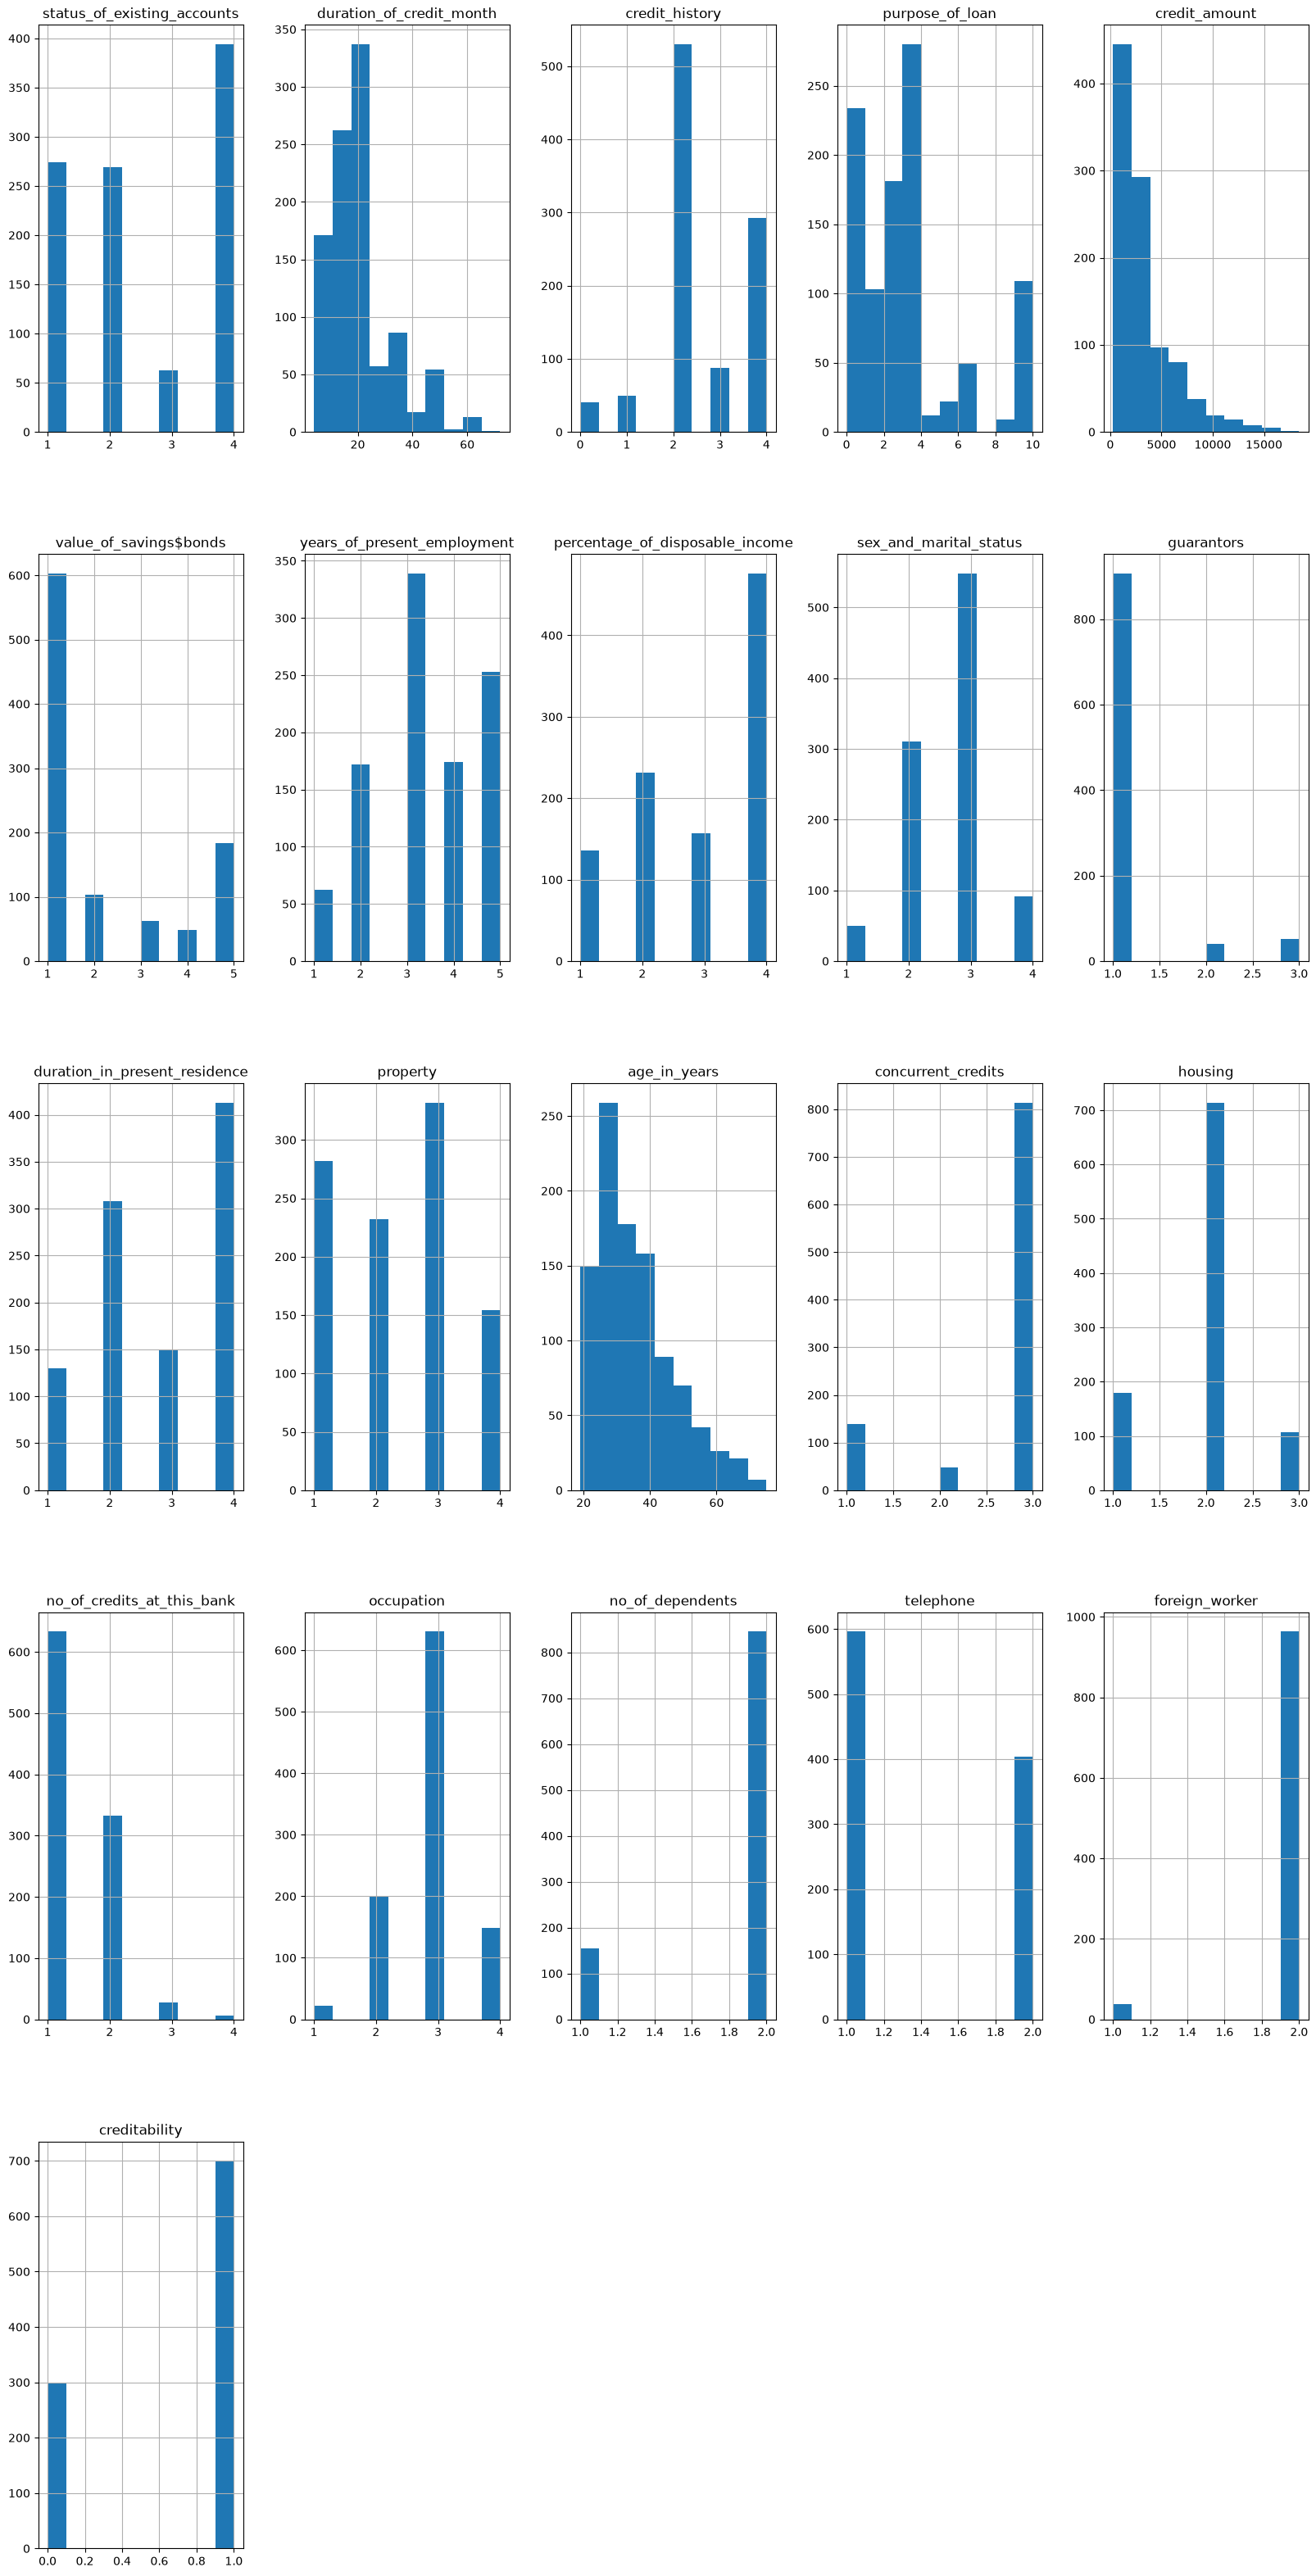

In [53]:
df.hist(figsize=(20,40))
plt.show()

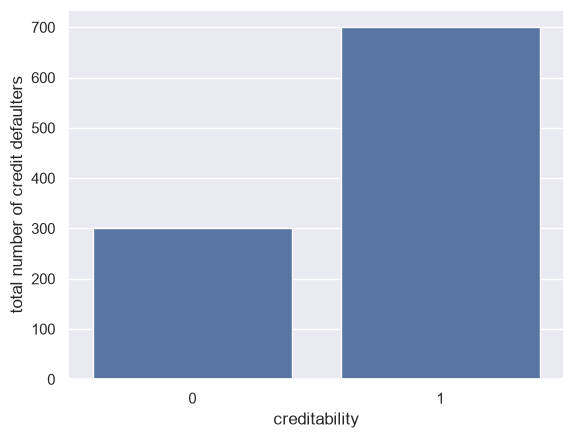

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(style="darkgrid")
plt.ylabel("total number of credit defaulters")
ax=sns.countplot(x="creditability",data=df)
plt.show()

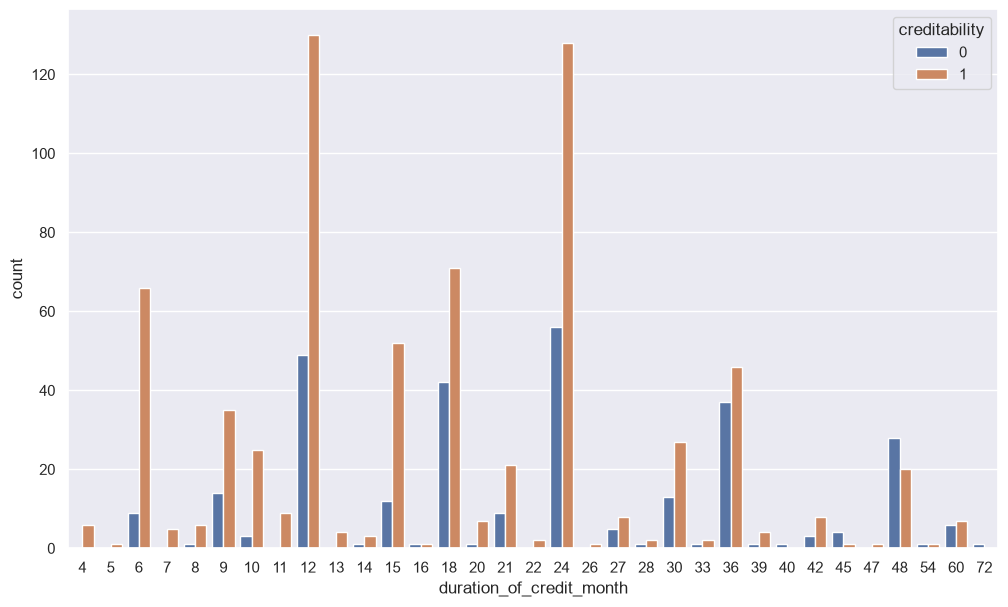

In [59]:
plt.figure(figsize=(12,7))
g=sns.countplot(x="duration_of_credit_month",hue="creditability",data=df)
plt.show()

In [63]:
#1 male : divorced/seperated
#2 female : divorced/married/seperated
#3 male : single
#4 male : married/widowed
#5 female: single

#purpose
0 : car(new)
1 : car(used)
2 : furniture
3
4
5
6
7
8
9
10

gender_df = df.groupby(["sex_and_marital_status","creditability"])["purpose_of_loan"].value_counts()
gender_df

sex_and_marital_status  creditability  purpose_of_loan
1                       0              2                  6
                                       9                  5
                                       0                  4
                                       3                  3
                                       6                  1
                                                         ..
4                       1              1                  5
                                       2                  5
                                       5                  2
                                       8                  2
                                       6                  1
Name: count, Length: 68, dtype: int64

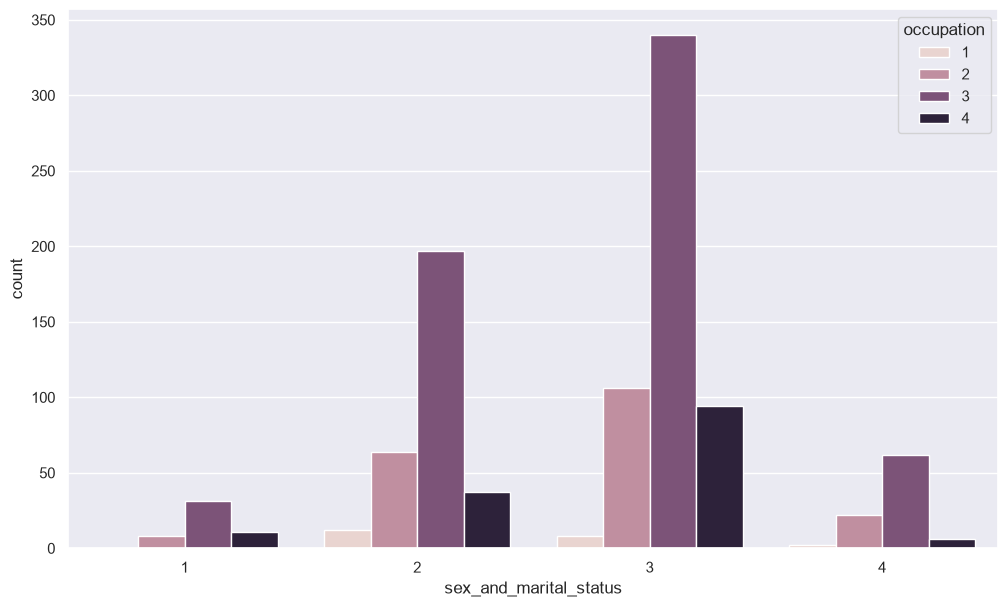

In [65]:
#1 = unemployed/unskilled -nonresident
#2 = unskilled -resident
#3 = skilled employee/official
#4 = self-employed, employee, officer, management

plt.figure(figsize=(12,7))
ax=sns.countplot(x='sex_and_marital_status',hue='occupation',data=df)
plt.show()

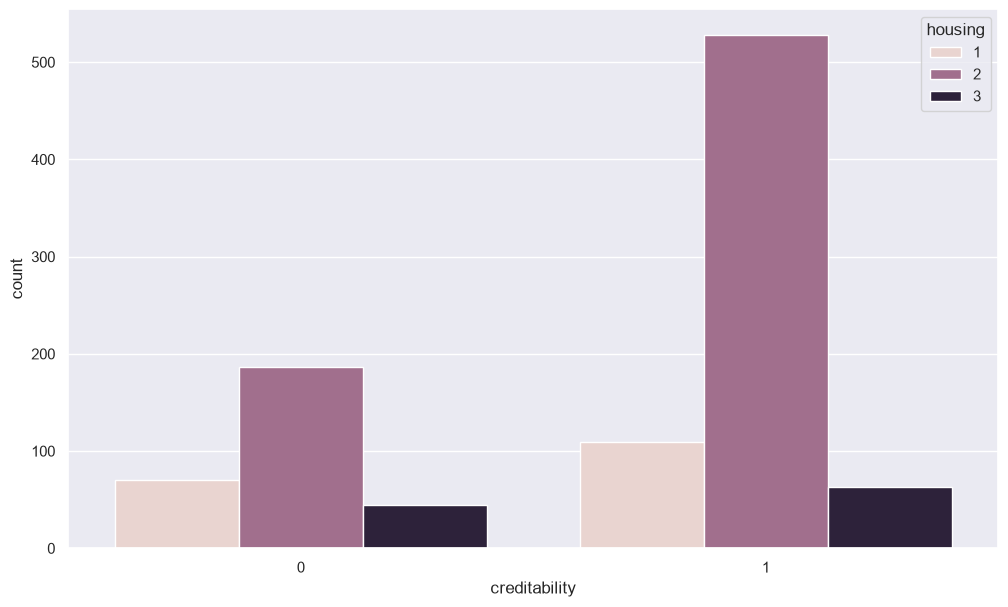

In [67]:
#1 = rent
#2 = own
#3 = for free

plt.figure(figsize=(12,7))
ax=sns.countplot(x="creditability",hue="housing",data=df)
plt.show()

# correlation

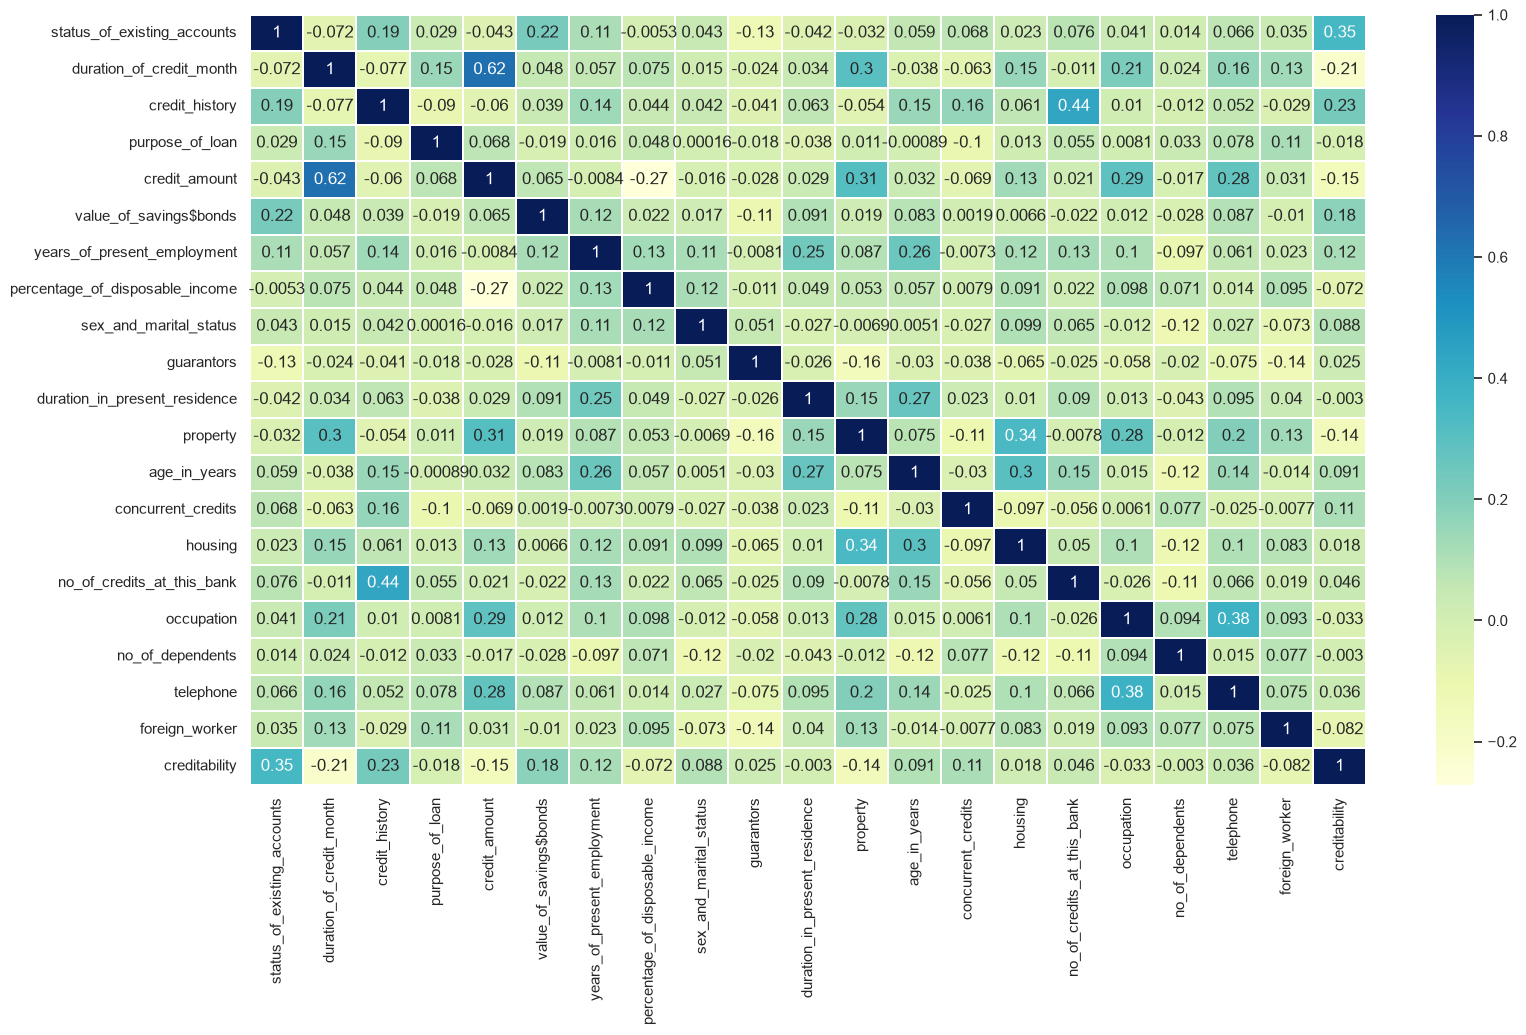

In [69]:
corr = df.corr()
plt.figure(figsize = (18,10))
sns.heatmap(corr,annot=True,cmap="YlGnBu",linewidth=0.1)
plt.show()

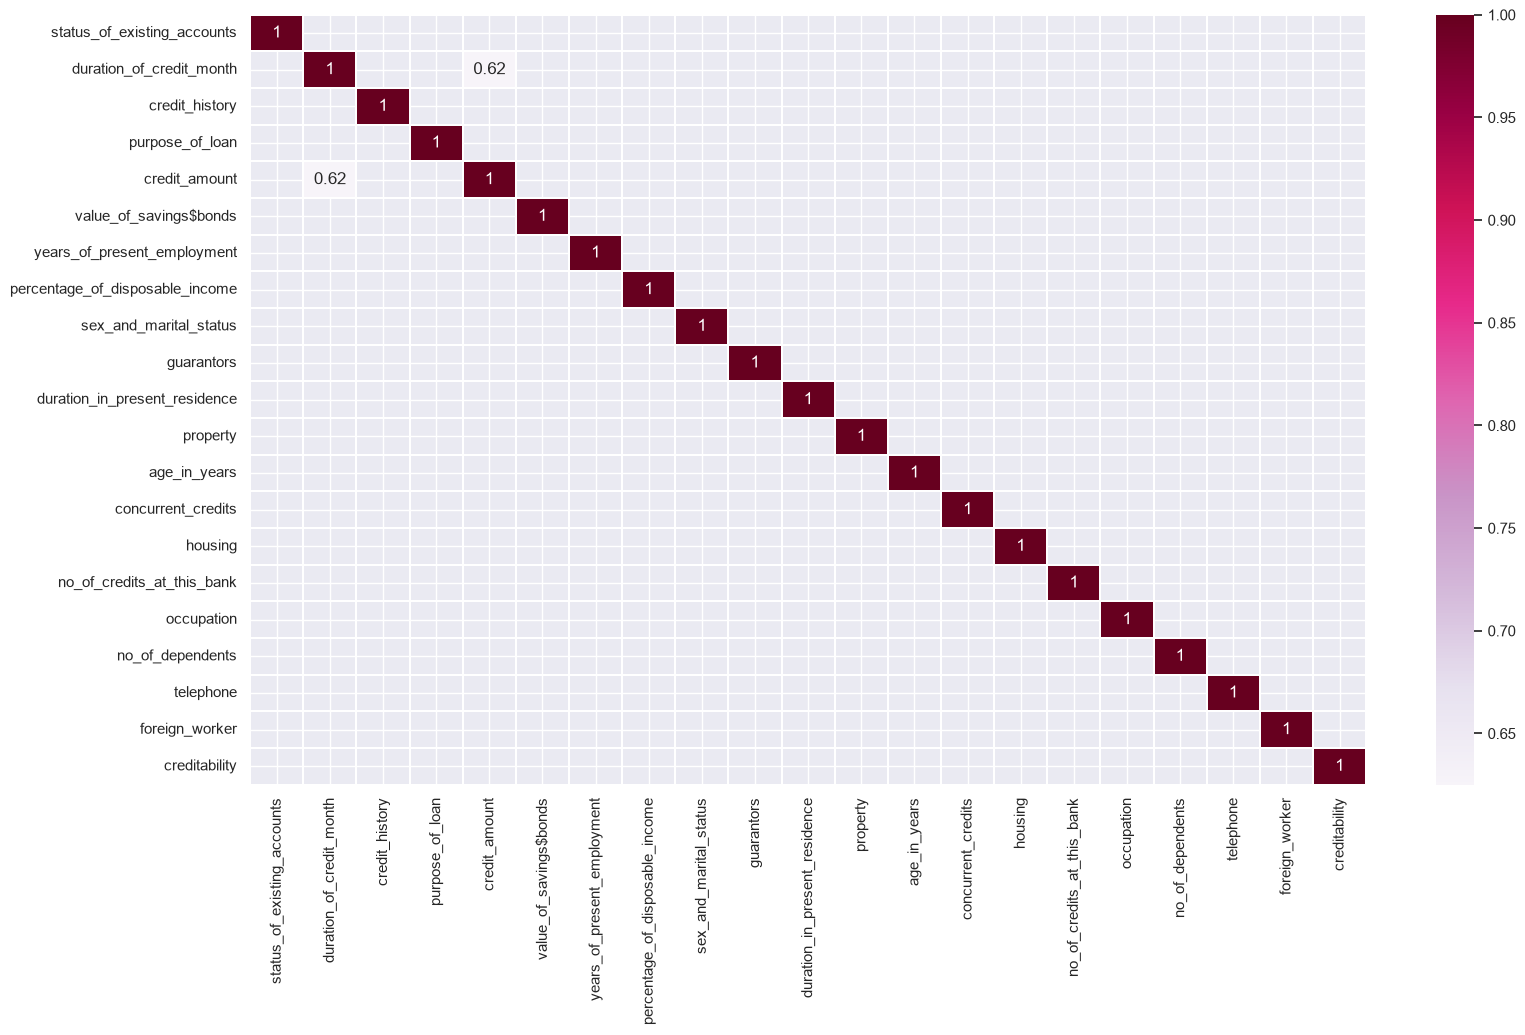

In [76]:
plt.figure(figsize=(18,10))
sns.heatmap(corr[(corr>=0.5)|(corr<=-0.5)],annot=True,linewidth=0.1,cmap="PuRd")
plt.show()

In [74]:
# Preparation of dataset
predictor = df.iloc[:,df.columns!="creditability"]
target = df.iloc[:,df.columns=="creditability"]

# split the dataset into train and test

In [77]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(predictor,target,random_state=1,test_size=0.30)
print("x_train",x_train.shape)
print("y_train",y_train.shape)
print("x_test",x_test.shape)
print("y_test",y_test.shape)

x_train (700, 20)
y_train (700, 1)
x_test (300, 20)
y_test (300, 1)


# Model Training

In [80]:
from sklearn.linear_model import LogisticRegression
#create an instance of Logistic Regression
logr = LogisticRegression()
#fit the data to the model
logr.fit(x_train,y_train)
y_pred = logr.predict(x_test)

In [81]:
y_pred

array([1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [82]:
#evaluate model
from sklearn import metrics
cnf_matrix = metrics.confusion_matrix(y_pred,y_test)
cnf_matrix

array([[ 42,  21],
       [ 49, 188]])

In [ ]:
#True Positive = actual result = CD predicts = CD 188
#True Negative = actual result = not CD predicts = not CD 42
#False Positive = actual result = not CD predicts = CD 21
#False Negative = actual result = CD predicts = not CD 49

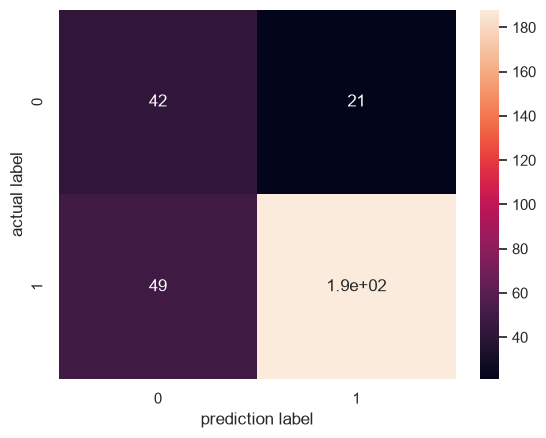

In [83]:
sns.heatmap(pd.DataFrame(cnf_matrix),annot=True)
plt.xlabel("prediction label")
plt.ylabel("actual label")
plt.show()

In [ ]:
#Accuracy = TP+TN/TP+TN+FP+FN
#Precision = TP/TP+FP   #how many customers are actually bad customers/CD
#Recall = TP/TP+FN      #how many did our model labelled as TRUE CD
#f1 score 

In [84]:
print("Accuracy:",metrics.accuracy_score(y_test,y_pred))
print("Precision:",metrics.precision_score(y_test,y_pred))
print("Recall:",metrics.recall_score(y_test,y_pred))

Accuracy: 0.7666666666666667
Precision: 0.7932489451476793
Recall: 0.8995215311004785


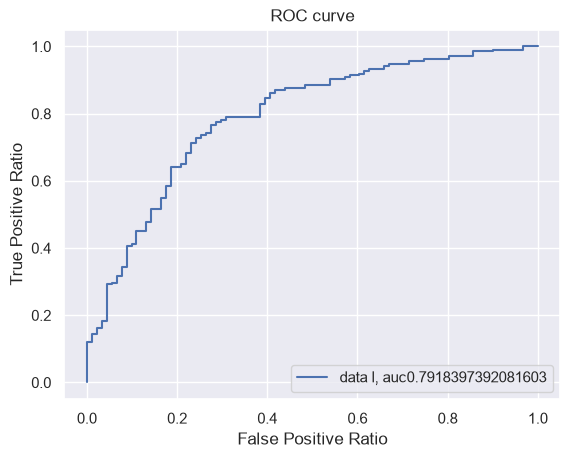

In [92]:
y_pred_proba = logr.predict_proba(x_test)[::,1]
fpr, tpr,_ = metrics.roc_curve(y_test,y_pred_proba)
auc = metrics.roc_auc_score(y_test,y_pred_proba)
plt.plot(fpr,tpr,label = "data l, auc"+str(auc))
plt.xlabel("False Positive Ratio")
plt.ylabel("True Positive Ratio")
plt.title("ROC curve")
plt.legend(loc=4)
plt.show()

In [98]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
kfold = KFold(n_splits=3, random_state=7, shuffle=True)
result = cross_val_score(logr,x_train,y_train,cv=kfold,scoring='accuracy')
print(result)

[0.72222222 0.78111588 0.75965665]


# Hyperparameters Tuning (to find the best settings for highest model accuracy)

In [107]:

# GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
import time

# Define hyperparameter values
dual = [True, False]
max_iter = [100, 110, 120, 130, 140]

# Create parameter grid
param_grid = dict(dual=dual, max_iter=max_iter)

# Initialize Logistic Regression
lr = LogisticRegression(penalty='l2', solver='liblinear')

# Initialize GridSearchCV
grid = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    cv=3,
    n_jobs=1,
    scoring='accuracy'
)

# Start timer
start_time = time.time()

# Fit the model
grid_result = grid.fit(x_train, y_train)

# Display best results
print("Best Accuracy: %f using %s" % (
    grid_result.best_score_,
    grid_result.best_params_
))

# Display execution time
print("Execution time: %.4f seconds" % (time.time() - start_time))

Best Accuracy: 0.729981 using {'dual': False, 'max_iter': 100}
Execution time: 0.1899 seconds


In [171]:
#RandomSearchCV
from sklearn.model_selection import RandomizedSearchCV
random = RandomizedSearchCV(estimator = lr,param_distributions=param_grid, cv=3, n_jobs=1)
start_time = time.time()
random_result = random.fit(x_train,y_train)

#summerize the result
print("Best score: %f using %s" % (random_result.best_score_, random_result.best_params_))
print("Execution time" +str((time.time() - start_time)) + "ms")

Best score: 0.729981 using {'max_iter': 100, 'dual': False}
Execution time0.18179106712341309ms


# Decision Tree

## Import Libraries

In [112]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

## Training Classifier

In [135]:
#create a decision tree object
dt = DecisionTreeClassifier(max_depth=3) #criterion & max_depth to restrict/cutdown the height of the tree
#train decision tree using classifier
dt = dt.fit(x_train,y_train)
#predict the response from the test data
y_pred = dt.predict(x_test)

In [136]:
print("Accuracy:",metrics.accuracy_score(y_test,y_pred))

Accuracy: 0.7333333333333333


## Visualizing Graph

In [137]:
from sklearn.tree import export_graphviz
from IPython.display import Image
import pydotplus
from io import StringIO
from sklearn import tree
import collections

In [138]:
feature_columns = ['status_of_existing_accounts', 'duration_of_credit_month',
       'credit_history', 'purpose_of_loan', 'credit_amount',
       'value_of_savings$bonds', 'years_of_present_employment',
       'percentage_of_disposable_income', 'sex_and_marital_status',
       'guarantors', 'duration_in_present_residence', 'property',
       'age_in_years', 'concurrent_credits', 'housing',
       'no_of_credits_at_this_bank', 'occupation', 'no_of_dependents',
       'telephone', 'foreign_worker']

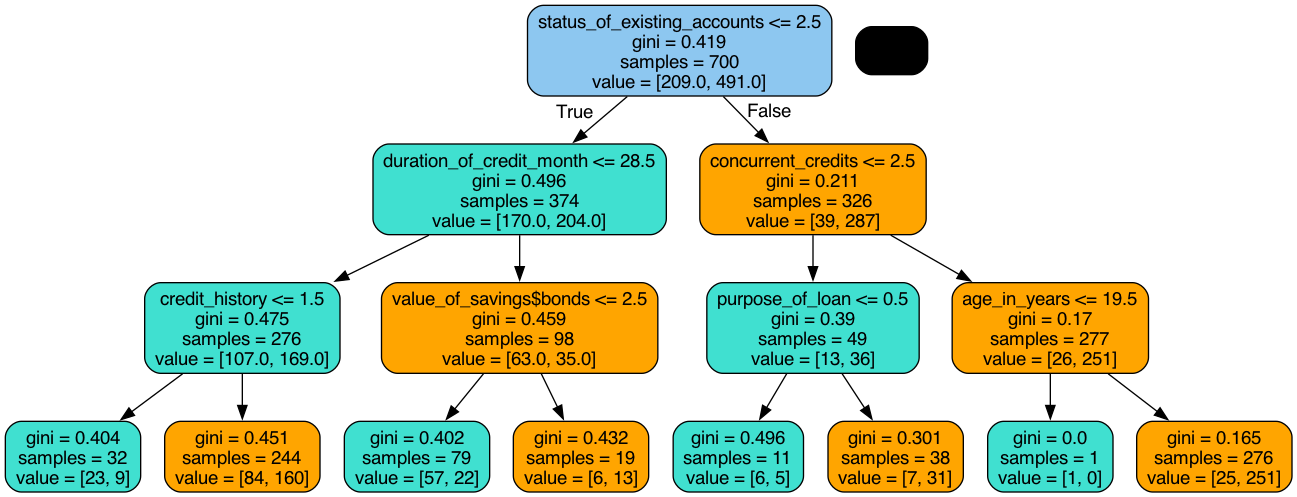

In [140]:
from sklearn.tree import export_graphviz
from IPython.display import Image
import pydotplus
import collections

# Visualize decision tree
dot_data = export_graphviz(
    dt,
    feature_names=feature_columns,
    out_file=None,
    filled=True,
    rounded=True
)

graph = pydotplus.graph_from_dot_data(dot_data)

colors = ('turquoise', 'orange')
edges = collections.defaultdict(list)

for edge in graph.get_edge_list():
    edges[edge.get_source()].append(int(edge.get_destination()))

for edge in edges:
    edges[edge].sort()

    for i in range(min(2, len(edges[edge]))):
        dest = graph.get_node(str(edges[edge][i]))[0]
        dest.set_fillcolor(colors[i])

graph.write_png('tree.png')
Image(graph.create_png())

# Random Forest

In [169]:
#Import Random Forest Model
from sklearn.ensemble import RandomForestClassifier

#Create a Gaussian Classifier
clf=RandomForestClassifier(n_estimators=100, max_depth=7)

#Train the model using the training sets y_pred=clf.predict(x_test)
clf.fit(x_train,y_train)

y_pred=clf.predict(x_test)

In [170]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

#Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.7633333333333333
